In [46]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [47]:
image_np = cv2.imread('input_imgs/Lenna_(test_image).png', cv2.IMREAD_GRAYSCALE)

In [48]:
image_np.shape

(512, 512)

In [49]:
sharp_kernel_3_3 = np.array([
    [0, -1, 0],
    [-1, 5,-1],
    [0, -1, 0]
])

blur_kernel_3_3 = np.ones((3,3))

In [50]:
def sliding_window_opencv(image, kernel, original_size, stride=1):

    filtered = cv2.filter2D(image, cv2.CV_32F, kernel, borderType=cv2.BORDER_CONSTANT)

    kernel_padding_h = kernel.shape[0] // 2
    kernel_padding_w = kernel.shape[1] // 2

    valid = filtered[
        kernel_padding_h:-kernel_padding_h,
        kernel_padding_w:-kernel_padding_w
    ]

    if original_size:
        return filtered[::stride, ::stride]
    else:
        return valid[::stride, ::stride]

Text(0.5, 1.0, 'Original, (52, 52)')

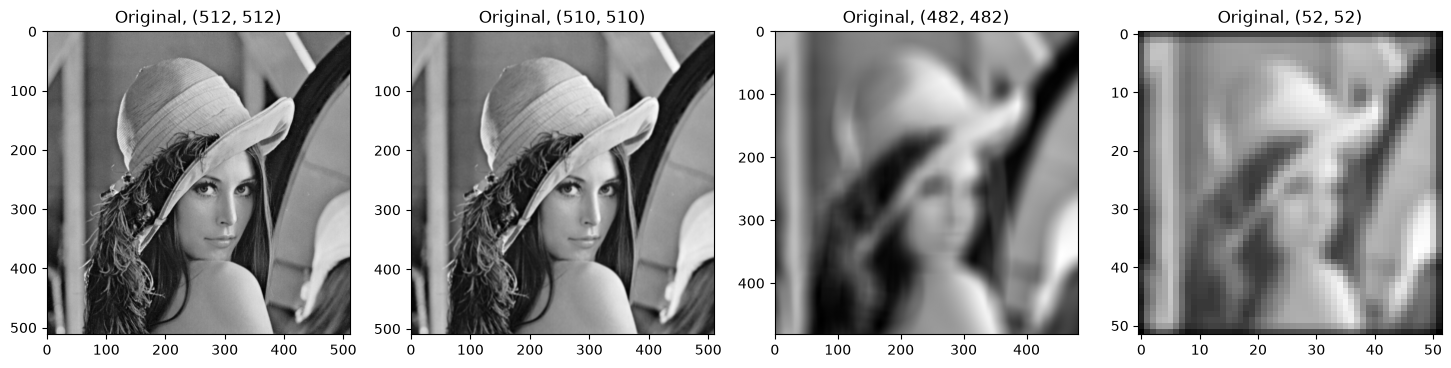

In [51]:
fig, axes = plt.subplots(1, 4, figsize=(18,10))

axes[0].imshow(image_np, cmap='gray')
axes[0].set_title(f'Original, {image_np.shape}')

res_1 = sliding_window_opencv(image_np, blur_kernel_3_3, original_size=False)
axes[1].imshow(res_1, cmap='gray')
axes[1].imshow(res_1, cmap='gray')
axes[1].set_title(f'Original, {res_1.shape}')

res_2 = sliding_window_opencv(image_np, np.ones((31,31)), original_size=False)
axes[2].imshow(res_2, cmap='gray')
axes[2].set_title(f'Original, {res_2.shape}')

res_3 = sliding_window_opencv(image_np, np.ones((31,31)), original_size=True, stride=10)
axes[3].imshow(res_3, cmap='gray')
axes[3].imshow(res_3, cmap='gray')
axes[3].set_title(f'Original, {res_3.shape}')

In [52]:
sharp_kernel_3_3 = np.array([
    [0, -1, 0],
    [-1, 5,-1],
    [0, -1, 0]
])

sharp_kernel_5_5 = np.array([
    [-1,-1,-1,-1,-1],
    [-1, 2, 2, 2,-1],
    [-1, 2, 8, 2,-1],
    [-1, 2, 2, 2,-1],
    [-1,-1,-1,-1,-1]
])

sharp_kernel_5_5_strong = np.array([
    [-1,-1,-1,-1,-1],
    [-1,-1,-1,-1,-1],
    [-1,-1,25,-1,-1],
    [-1,-1,-1,-1,-1],
    [-1,-1,-1,-1,-1]
])

Text(0.5, 1.0, 'Original, (128, 128)')

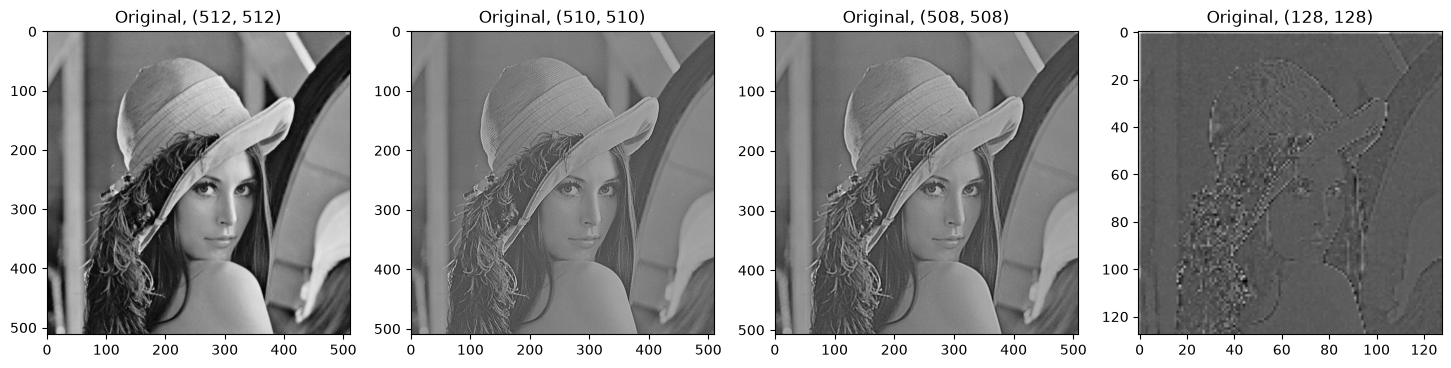

In [53]:
fig, axes = plt.subplots(1, 4, figsize=(18,10))

axes[0].imshow(image_np, cmap='gray')
axes[0].set_title(f'Original, {image_np.shape}')

res_1 = sliding_window_opencv(image_np, sharp_kernel_3_3, original_size=False)
axes[1].imshow(res_1, cmap='gray')
axes[1].set_title(f'Original, {res_1.shape}')

res_2 = sliding_window_opencv(image_np, sharp_kernel_5_5, original_size=False)
axes[2].imshow(res_2, cmap='gray')
axes[2].set_title(f'Original, {res_2.shape}')

res_3 = sliding_window_opencv(image_np, sharp_kernel_5_5_strong, original_size=True, stride=4)
axes[3].imshow(res_3, cmap='gray')
axes[3].imshow(res_3, cmap='gray')
axes[3].set_title(f'Original, {res_3.shape}')

Text(0.5, 1.0, 'Original, (128, 128)')

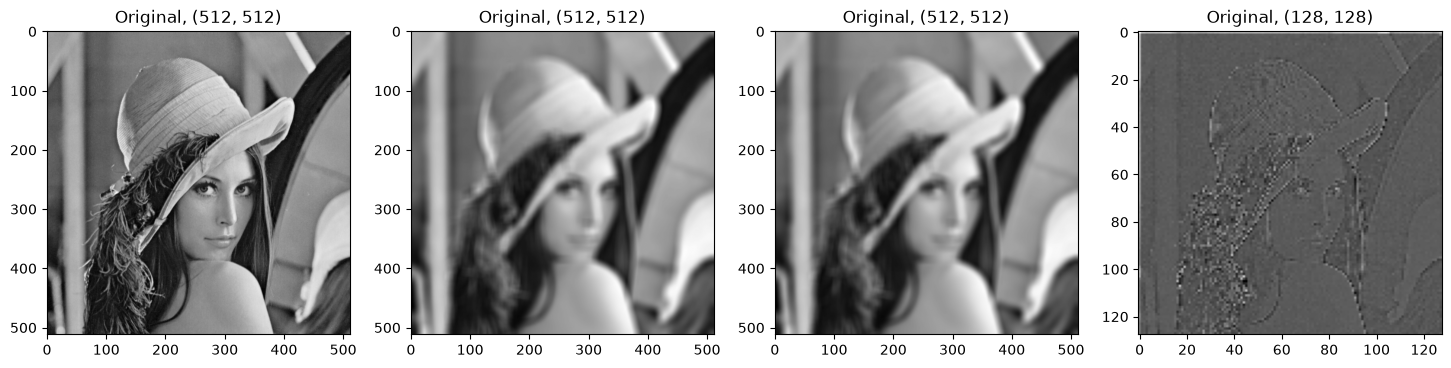

In [54]:
fig, axes = plt.subplots(1, 4, figsize=(18,10))

axes[0].imshow(image_np, cmap='gray')
axes[0].set_title(f'Original, {image_np.shape}')

res_1 = cv2.blur(image_np, (15,15))
axes[1].imshow(res_1, cmap='gray')
axes[1].set_title(f'Original, {res_1.shape}')

res_2 = cv2.GaussianBlur(image_np, (15,15), sigmaX=10)
axes[2].imshow(res_2, cmap='gray')
axes[2].set_title(f'Original, {res_2.shape}')

res_3 = sliding_window_opencv(image_np, sharp_kernel_5_5_strong, original_size=True, stride=4)
axes[3].imshow(res_3, cmap='gray')
axes[3].imshow(res_3, cmap='gray')
axes[3].set_title(f'Original, {res_3.shape}')